# Setup

In [1]:
# Base class
from src.Base.Config import Config

# Project class
from src.BetaMouv.Trajectory import TrajectoryDLC, DLCTracking
import src.BetaMouv.Behavior as Behavior
import src.utils as u

# other lib
from pathlib import Path
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
cfg = Config(Path("./config.yaml"))
project = cfg.load_project()

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme("talk", style="ticks", rc=custom_params, palette="pastel")

analysis_dir = u.make_dir(project.paths.analysis(project.trialgroup.keep_val))
df_dir = u.make_dir(analysis_dir / "trials_df")

project.trialgroup.crop_laser_period = True
project.trialgroup.remove_NOstim = True

log: config unchanged (config_20261029_155357.yaml)

 CONTRA_CHR_#517_#531


### Load joblib trials
can take a bit of time

In [11]:
project.trialgroup.load_trials()

Loading joblib: 100%|██████████| 228/228 [00:05<00:00, 44.78it/s] 

--> 59/228 FILES LOADED
--> 4933 trials


In [35]:
BODYPARTS = [
    "Hand_base",
    "Base_finger_2",
    "Base_finger_3",
    "Phalanx_1_finger_2",
    "Phalanx_1_finger_3",
    "finger_1",
    "finger_2",
    "finger_3",
    "soft_pad",
    "Front_PAD_corner",
    "Back_PAD_corner",
    "Lever_ball",
    "Lever_base",
    "Lever_corner",
    "hand", 
    "wrist",
]
output_dir = project.paths.data_root / "keypoint_moseq" / "dlc_data"
output_dir.mkdir(parents=True, exist_ok=True)

In [36]:
print(BODYPARTS)
print(len(BODYPARTS))

['Hand_base', 'Base_finger_2', 'Base_finger_3', 'Phalanx_1_finger_2', 'Phalanx_1_finger_3', 'finger_1', 'finger_2', 'finger_3', 'soft_pad', 'Front_PAD_corner', 'Back_PAD_corner', 'Lever_ball', 'Lever_base', 'Lever_corner', 'hand', 'wrist']
16


In [38]:
n_trial = 200
n=0

for trial in tqdm(project.trialgroup.trials, desc="cropping"):
    if n>n_trial: 
        break
    if not trial.is_valid() or trial.date.month == 5:
        continue

    save_as: Path = output_dir / f"{trial.name}.csv"
    # if save_as.exists(): 
    #     continue

    tracking = DLCTracking(path=trial.pred_path,
                                view=trial.camera_view, 
                                bodyparts=BODYPARTS,
                                time_pad_off=trial.time_pad_off,
                                cm_per_pixel=trial.cm_per_pixel,
                                shift=trial.camera_shift)
    coords_set = tracking.load(False)
    for bp, traj in coords_set.items(): 
        traj.coords = traj.crop_xy(start=trial.time_pad_off - 0.1, end=trial.time_pad_off + 0.4)

    # format saving
    data = {bp: traj.coords.set_index("t")
        for bp, traj in coords_set.items()}

    df = pd.concat({tracking.scorer: pd.concat(data, axis=1)}, axis=1, names=["scorer", "bodyparts", "coords"])
    if  len(df) != 63: 
        continue

    # Replace index with frame_num (0, 1, ..., len(df)-1)
    df.index = pd.RangeIndex(start=0, stop=len(df), name="frame_num")

    df.to_csv(output_dir / f"{trial.name}.csv")
    n+=1



cropping:   0%|          | 0/4933 [00:00<?, ?it/s]

cropping:   7%|▋         | 326/4933 [00:07<01:50, 41.52it/s]


In [21]:
traj_data = []

n=0
for trial in project.trialgroup.trials:
    if not trial.is_valid():
        continue

    for bp, stat in trial.trajectories.items():
        data = {info: val for  info, val in stat.items()}
        data["id"] = n
        data["trial_name"] = trial.name

        traj_data.append(data)


traj_data_df = pd.DataFrame(traj_data)
traj_data_df.to_csv("traj_data_df.csv")

## Success rate

In [22]:
project.trialgroup.build_df(df_dir, "trial_success")
project.trialgroup.build_df(df_dir, "bodypart_success")


'trial_success' already exist: 'data/BetaMouv/results/CONTRA_CHR_#517_#525_#521_#531/trials_df/trial_success.csv'
Loading...

'bodypart_success' already exist: 'data/BetaMouv/results/CONTRA_CHR_#517_#525_#521_#531/trials_df/bodypart_success.csv'
Loading...


,name,clip_path,date,camera_view,clip_number,laser_intensity,handedness,laser_type,subject,condition,...,time_pad_off,time_laser_on,time_reward,group,trial_outcomes,camera_shift,bodypart,stage,success,reason
0,Rat_#517Ambidexter_20240705_BetaMT300_RightHem...,data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...,2024-07-05,left,7,high,Ambidexter,Beta,#517,CHR,...,0.272,0.296,0.552,#517_CHR_CONTRA_Beta_RightHemi_leftView_high_L...,{'clip_openable': Outcome(stage='clip_openable...,"(0.046, 0.023)",Hand_base,outlier,True,0 out
1,Rat_#517Ambidexter_20240705_BetaMT300_RightHem...,data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...,2024-07-05,left,7,high,Ambidexter,Beta,#517,CHR,...,0.272,0.296,0.552,#517_CHR_CONTRA_Beta_RightHemi_leftView_high_L...,{'clip_openable': Outcome(stage='clip_openable...,"(0.046, 0.023)",Hand_base,validation,True,0 out
2,Rat_#517Ambidexter_20240705_BetaMT300_RightHem...,data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...,2024-07-05,left,7,high,Ambidexter,Beta,#517,CHR,...,0.272,0.296,0.552,#517_CHR_CONTRA_Beta_RightHemi_leftView_high_L...,{'clip_openable': Outcome(stage='clip_openable...,"(0.046, 0.023)",Base_finger_2,outlier,True,0 out
3,Rat_#517Ambidexter_20240705_BetaMT300_RightHem...,data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...,2024-07-05,left,7,high,Ambidexter,Beta,#517,CHR,...,0.272,0.296,0.552,#517_CHR_CONTRA_Beta_RightHemi_leftView_high_L...,{'clip_openable': Outcome(stage='clip_openable...,"(0.046, 0.023)",Base_finger_2,validation,True,0 out
4,Rat_#517Ambidexter_20240705_BetaMT300_RightHem...,data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...,2024-07-05,left,7,high,Ambidexter,Beta,#517,CHR,...,0.272,0.296,0.552,#517_CHR_CONTRA_Beta_RightHemi_leftView_high_L...,{'clip_openable': Outcome(stage='clip_openable...,"(0.046, 0.023)",Base_finger_3,outlier,True,0 out
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70807,Rat_#521RightHanded_20240528_Session1_ContiMT3...,data/BetaMouv/raw/subject_#521/Rat_#521RightHa...,2024-05-28,right,21,low,RightHanded,Conti,#521,CHR,...,0.280,0.304,NaN,#521_CHR_CONTRA_Conti_LeftHemi_rightView_low_L...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.418, -1.113)",Lever_ball,validation,True,few out
70808,Rat_#521RightHanded_20240528_Session1_ContiMT3...,data/BetaMouv/raw/subject_#521/Rat_#521RightHa...,2024-05-28,right,21,low,RightHanded,Conti,#521,CHR,...,0.280,0.304,NaN,#521_CHR_CONTRA_Conti_LeftHemi_rightView_low_L...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.418, -1.113)",Lever_base,outlier,False,out cons>5
70809,Rat_#521RightHanded_20240528_Session1_ContiMT3...,data/BetaMouv/raw/subject_#521/Rat_#521RightHa...,2024-05-28,right,21,low,RightHanded,Conti,#521,CHR,...,0.280,0.304,NaN,#521_CHR_CONTRA_Conti_LeftHemi_rightView_low_L...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.418, -1.113)",Lever_base,validation,False,out cons>5
70810,Rat_#521RightHanded_20240528_Session1_ContiMT3...,data/BetaMouv/raw/subject_#521/Rat_#521RightHa...,2024-05-28,right,21,low,RightHanded,Conti,#521,CHR,...,0.280,0.304,NaN,#521_CHR_CONTRA_Conti_LeftHemi_rightView_low_L...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.418, -1.113)",Lever_corner,outlier,True,few out


In [23]:
project.trialgroup.trial_success_rate(u.make_path(analysis_dir, "trial_success_rate.png"))

Report saved to: data/BetaMouv/results/CONTRA_CHR_#517_#525_#521_#531/trial_success_rate.png


In [24]:
project.trialgroup.trajectories_success_rate(u.make_path(analysis_dir, "trajectories_success_rate.png"))

Report saved to: data/BetaMouv/results/CONTRA_CHR_#517_#525_#521_#531/trajectories_success_rate.png


In [25]:

project.trialgroup.sunburst_metadata(output_dir=u.make_dir(analysis_dir / "metadata_sunburst"),
                                  subfig_group="subject", 
                                  groups=["laser_type"],
                                  title=project.trialgroup.group_name)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [ ]:
project.trialgroup.sunburst_metadata(output_dir=u.make_dir(analysis_dir / "metadata_sunburst"), 
                                  subfig_group="condition", 
                                  groups=["subject", "laser_type", "laser_intensity"],
                                  title=project.trialgroup.group_name)

In [ ]:
project.trialgroup.sunburst_metadata(output_dir=u.make_dir(analysis_dir / "metadata_sunburst"), 
                                  subfig_group=None, 
                                  groups=["subject", "is_valid", "failing_step"],
                                  title=project.trialgroup.group_name)



## Behavior analysis

In [3]:
project.trialgroup.build_df(df_dir, "behavior")


'behavior' already exist: 'data/BetaMouv/results/CONTRA_CHR_#517_#531/trials_df/behavior.csv'
Loading...


,x,y,t,area,centroid_direction,centroid_velocity,centroid_speed,centroid_acc,f3_sp_distance,f3_sp_angle,...,movement_type,cue_type,time_pad_off,time_laser_on,time_reward,group,trial_outcomes,camera_shift,index_order,relative_t
0,2.551710,2.973760,0.000,0.011976,NaN,NaN,NaN,NaN,0.642908,-5.594495,...,CONTRA,CueL1,0.184,NaN,1.072,#517_CHR_CONTRA_Conti_RightHemi_leftView_high_...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.205, -0.429)",0,-0.184
1,2.551361,2.973865,0.008,0.011609,16.796600,0.045498,0.045498,NaN,0.643405,-5.576808,...,CONTRA,CueL1,0.184,NaN,1.072,#517_CHR_CONTRA_Conti_RightHemi_leftView_high_...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.205, -0.429)",1,-0.176
2,2.553845,2.973129,0.016,0.011616,-163.497685,-0.323777,0.323777,-46.159357,0.649007,-5.469630,...,CONTRA,CueL1,0.184,NaN,1.072,#517_CHR_CONTRA_Conti_RightHemi_leftView_high_...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.205, -0.429)",2,-0.168
3,2.552307,2.971066,0.024,0.011407,-53.301373,-0.321645,0.321645,0.266499,0.645787,-5.230812,...,CONTRA,CueL1,0.184,NaN,1.072,#517_CHR_CONTRA_Conti_RightHemi_leftView_high_...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.205, -0.429)",3,-0.160
4,2.550399,2.971669,0.032,0.011960,17.535986,0.250160,0.250160,71.475691,0.639816,-5.433515,...,CONTRA,CueL1,0.184,NaN,1.072,#517_CHR_CONTRA_Conti_RightHemi_leftView_high_...,{'clip_openable': Outcome(stage='clip_openable...,"(-0.205, -0.429)",4,-0.152
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
450546,1.282921,5.085908,1.936,0.010362,60.782863,0.033284,0.033284,-3.192030,0.401398,11.160366,...,CONTRA,CueL1,0.392,NaN,NaN,#517_CHR_CONTRA_Conti_RightHemi_leftView_low_L...,{'clip_openable': Outcome(stage='clip_openable...,"(-18.44, 22.244)",242,1.544
450547,1.282692,5.086278,1.944,0.010530,58.220323,0.054487,0.054487,2.650303,0.401481,11.073523,...,CONTRA,CueL1,0.392,NaN,NaN,#517_CHR_CONTRA_Conti_RightHemi_leftView_low_L...,{'clip_openable': Outcome(stage='clip_openable...,"(-18.44, 22.244)",243,1.552
450548,1.282841,5.086577,1.952,0.010500,116.568528,-0.041741,0.041741,-12.028453,0.401622,11.199899,...,CONTRA,CueL1,0.392,NaN,NaN,#517_CHR_CONTRA_Conti_RightHemi_leftView_low_L...,{'clip_openable': Outcome(stage='clip_openable...,"(-18.44, 22.244)",244,1.560
450549,1.282813,5.089763,1.960,0.008343,89.502745,0.398276,0.398276,55.002198,0.402833,12.240814,...,CONTRA,CueL1,0.392,NaN,NaN,#517_CHR_CONTRA_Conti_RightHemi_leftView_low_L...,{'clip_openable': Outcome(stage='clip_openable...,"(-18.44, 22.244)",245,1.568


In [109]:
features = [
            # "relative_t",
            "x", 
            "y",
            "area", 
            "centroid_direction", 
            "centroid_velocity", 
            # "centroid_speed", 
            # "centroid_acc", 
            "f3_sp_distance", 
            "f3_sp_angle", 
            "centroid_lever_dist"
]

### PCA

In [110]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [111]:
labels = [
    "name", "date", "subject", "spatial_behavior", "t",
    "laser_type", "laser_state", "condition", "laser_intensity"
]
BEHAVIOR_PALETTE = {
    "reach":"yellow", 
    "open":"orange", 
    "grasp":"blue", 
    "press":"green", 
    "none":"gray"
}

In [112]:
raw_df = project.trialgroup.clean_df(project.trialgroup._behavior_df)
raw_df = raw_df[features + labels].dropna()
label_df = raw_df[labels]
df = raw_df[features]
print(len(label_df), len(df))
print(raw_df.columns)
print(df.columns)

77224 77224
Index(['x', 'y', 'area', 'centroid_direction', 'centroid_velocity',
       'f3_sp_distance', 'f3_sp_angle', 'centroid_lever_dist', 'name', 'date',
       'subject', 'spatial_behavior', 't', 'laser_type', 'laser_state',
       'condition', 'laser_intensity'],
      dtype='object')
Index(['x', 'y', 'area', 'centroid_direction', 'centroid_velocity',
       'f3_sp_distance', 'f3_sp_angle', 'centroid_lever_dist'],
      dtype='object')


In [113]:

# X is your DataFrame containing features
X = df.select_dtypes(include="number")

# 1. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 3. Store results in a new DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=df.index
).join(label_df)

pca_df.head()

,PC1,PC2,name,date,subject,spatial_behavior,t,laser_type,laser_state,condition,laser_intensity
11,1.799122,-1.075952,Rat_#517Ambidexter_20240711_Session2_ContiMT30...,2024-07-11,#517,none,0.088,Conti,LaserOff,CHR,high
12,1.838197,-1.029429,Rat_#517Ambidexter_20240711_Session2_ContiMT30...,2024-07-11,#517,none,0.096,Conti,LaserOff,CHR,high
13,1.899106,-0.909552,Rat_#517Ambidexter_20240711_Session2_ContiMT30...,2024-07-11,#517,none,0.104,Conti,LaserOff,CHR,high
14,1.913667,-0.903130,Rat_#517Ambidexter_20240711_Session2_ContiMT30...,2024-07-11,#517,none,0.112,Conti,LaserOff,CHR,high
15,2.006055,-0.824473,Rat_#517Ambidexter_20240711_Session2_ContiMT30...,2024-07-11,#517,none,0.120,Conti,LaserOff,CHR,high


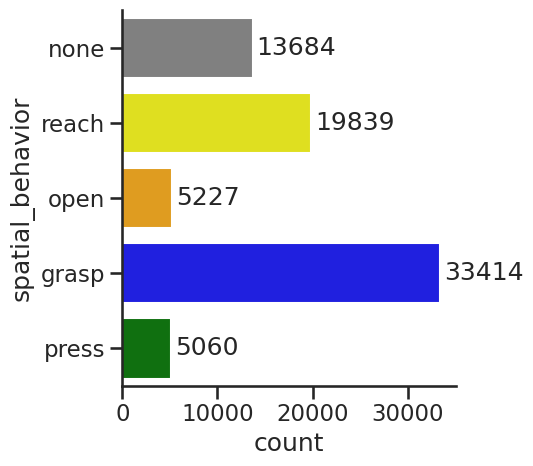

In [114]:
count = pca_df.groupby("spatial_behavior").count()
g = sns.catplot(
    data=pca_df, kind="count",
    y="spatial_behavior",
    hue="spatial_behavior", palette=BEHAVIOR_PALETTE,
)

# add count on bars
for ax in g.axes.flat: 
    for container in ax.containers: 
        ax.bar_label(container, fmt="%d", padding=3)


In [115]:
print(pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

[0.51491755 0.14204151]
Total explained variance: 0.6569590594967712


In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"]
)

loadings

,PC1,PC2
x,0.451032,-0.010289
y,-0.399620,0.314872
area,0.333281,0.192370
centroid_direction,0.279293,0.336637
centroid_velocity,0.087964,0.788945
f3_sp_distance,0.251870,0.206058
f3_sp_angle,-0.397552,0.281504
centroid_lever_dist,0.467515,-0.079247


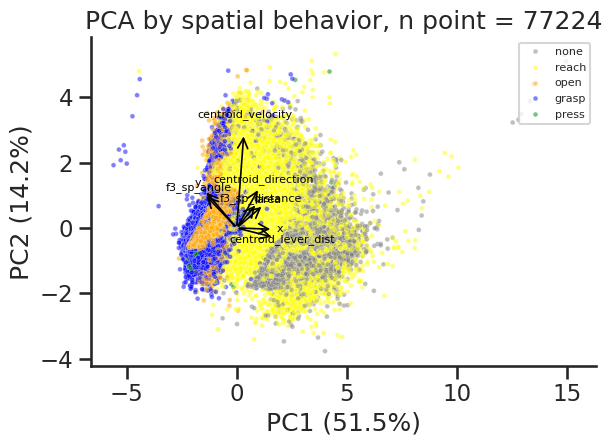

In [117]:
fig, ax = plt.subplots()

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="spatial_behavior",
    palette=BEHAVIOR_PALETTE, s=12,
    alpha=0.5, ax=ax, 
)

loadings = pca.components_.T 

scale = min(
    pca_df["PC1"].max() - pca_df["PC1"].min(), 
    pca_df["PC2"].max() - pca_df["PC2"].min()
) * 0.4

for i, feature in enumerate(features): 
    x_loading = loadings[i, 0] * scale
    y_loading = loadings[i, 1] * scale

    ax.annotate("", xy=(x_loading, y_loading), 
                xytext=(0, 0), 
                arrowprops=dict(arrowstyle="->", color="black", lw=1.2,))

    ax.text(x_loading*1.2, y_loading*1.2, feature, color="black", fontsize=8, ha="center", va="center")

ax.legend(loc="upper right", fontsize=8)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title(f"PCA by spatial behavior, n point = {len(pca_df)}")
plt.tight_layout()
plt.show()

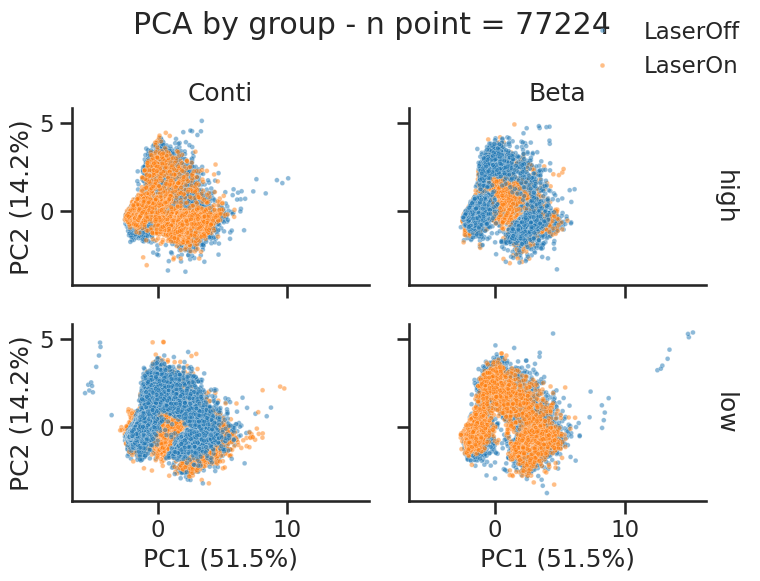

In [119]:
import matplotlib.pyplot as plt

g = sns.FacetGrid(data=pca_df, 
                  col="laser_type", 
                  row="laser_intensity",
                  margin_titles=True,)

g.map_dataframe(
    sns.scatterplot,
    x="PC1",
    y="PC2",
    hue="laser_state", 
    palette="tab10",
    alpha=0.5, s=12
)
g.add_legend(loc="upper right")
g.set_axis_labels(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})", 
                  f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
g.set_titles(row_template="{row_name}", col_template="{col_name}")
g.figure.suptitle(f"PCA by group - n point = {len(pca_df)}")
plt.tight_layout()
plt.show()

Below is a feature set organised by what it captures. It assumes a fixed camera, 2D tracking, and a lever/pad setup where the reach ends in a lever press or grasp. Adjust if your setup differs.

## 0. Preprocessing before any feature
- **Reference frame:** express hand points relative to the task geometry, not raw pixels. Use `Lever_base`→`Lever_corner` or the pad corners as the axes, so features are invariant to small camera or setup shifts.
- **Scale:** convert to mm using a known distance (pad length, lever length), or normalise by hand size (e.g. median `wrist`–`Hand_base` distance).
- **Smoothing:** apply Savitzky-Golay or a low-pass filter *before* differentiating. Derivatives amplify the noise left after interpolation.
- **Angles:** encode them as sin/cos, or unwrap them, so wrap-around at ±180° doesn't create fake jumps.

## 1. Hand transport (where the hand goes)
- x/y of `wrist`, `Hand_base`, `hand` (and the centroid of the hand points), relative to `Lever_ball` and the pad.
- Speed, acceleration, jerk, and velocity direction angle for `wrist` and `Hand_base`.
- Distance from the hand to `Lever_ball`, the lever line, `Front_PAD_corner` and `Back_PAD_corner`.
- Path-based, per-trial measures: path length, straightness (straight-line distance / path length), curvature, number of velocity peaks (sub-movements), peak speed and time to peak.

## 2. Hand orientation
- Angle of the `wrist`→`Hand_base` vector, as a pronation/supination or tilt proxy, plus its angular velocity.
- Angle of that vector relative to the lever axis.
- Angle of `Hand_base`→`soft_pad`, and the palm-side orientation.

## 3. Finger configuration (the grasp)
- **Joint angles** for each finger chain, e.g. `Hand_base`–`Base_finger_2`–`Phalanx_1_finger_2`, and `Base_finger_2`–`Phalanx_1_finger_2`–`finger_2`. Same for finger 3. These give flexion/extension.
- **Finger extension ratio:** distance(`Hand_base`, fingertip) / maximal finger length. This is a robust, scale-free measure.
- **Aperture:** distances `finger_1`–`finger_2`, `finger_1`–`finger_3`, and `finger_2`–`finger_3`.
- **Finger spread angle:** angle between `Hand_base`→`Base_finger_2` and `Hand_base`→`Base_finger_3`.
- **Hand area:** convex hull or polygon area over the hand points, a compact open/closed measure.
- Angular velocities of the above, so you can separate opening from closing.

## 4. Hand–object interaction
- Fingertip, `soft_pad` and `hand` distance to `Lever_ball` (minimum across fingers, and which finger is nearest).
- Lever state: lever angle (`Lever_base`→`Lever_ball` or `Lever_corner`), displacement, and velocity. This is your task outcome, so it is useful for labeling clusters.
- Contact proxies: distance below a threshold, plus the hand height relative to the pad plane (lift, touching, retracting).

## 5. Quality control features (don't cluster on them)
- Mean DLC likelihood per frame and the fraction of interpolated frames. Use these to check that clusters aren't driven by tracking artifacts.

## From features to clustering
- **Normalise and prune:** z-score or robust-scale, then drop highly correlated features. You'll end up with roughly 40–80 features, which is fine.
- **Choose a unit of analysis:**
  - *Per-frame or sliding-window* (e.g. 100–300 ms windows with mean, std, min and max of each feature): best for discovering sub-movements such as reach, pronate, grasp, retract. Follow with UMAP or PCA, then HDBSCAN or GMM.
  - *Per-trial summaries* (peak speed, duration, aperture at lever contact, etc.): best for comparing trials, sessions or animals.
  - *Time-warped trajectories* (DTW or fixed phase normalisation, then PCA or functional PCA): good for comparing reach shapes.
- **Align trials to an event** such as movement onset (speed threshold) or lever contact, and keep the phase of the trial (time since onset) as a feature or a colouring variable.
- **Cross-check:** compare your clusters against B-SOiD or Keypoint-MoSeq on the same keypoints. If the hand-crafted features and the unsupervised pose models agree, the labels are more trustworthy.

## Caveats
- With 2D tracking, angles are projections, so finger flexion can be confounded by hand rotation out of the image plane. Features that are most robust to this are distances normalised by hand size.
- Check which of your points are really independent. `hand`, `soft_pad` and `Hand_base` may be close together, so don't count them as three separate signals.

If you tell me the frame rate, whether the tracking is 2D or 3D, and what the pad and lever are used for (reward delivery, press threshold, etc.), I can narrow this to a shorter list and write the feature extraction code (pandas/numpy) for your DLC output format.

In [ ]:
plot_pcs_2d(pca, use_bodyparts=use_bodyparts, skeleton=skeleton, plot_n_pcs=6, ncols=3)

In [ ]:
for feat in features: 
    project.trialgroup.plot_tendency_beha_features(
                        save_as=u.make_path(analysis_dir / "behavior" / "with_behavior_span", f"{feat}.png"),
                        x="relative_t", y=feat, show_beha="spatial_behavior")

    project.trialgroup.plot_tendency_beha_features(
                        save_as=u.make_path(analysis_dir / "behavior", f"{feat}.png"),
                        x="relative_t", y=feat, show_beha=None)



In [4]:
project.trialgroup.lineplot_traj_centroid(save_as=u.make_path(analysis_dir / "behavior", f"centroid_traj_2.png"),) 

Distribution of each features, per protocols

In [ ]:
for l_type in ["Beta","Conti"] : 
    for l_intensity in ["low", "high"]: 
        for l_state in ["LaserOn", "LaserOff"] : 
            project.trialgroup.distri_feat_per_behavior(behavior_varname="spatial_behavior", laser_type=l_type, laser_intensity=l_intensity, laser_state=l_state,
                                                    save_as=u.make_path(analysis_dir / "behavior" / "distri_feat_per_behavior", f"spatial_behavior_{l_type}_{l_intensity}_{l_state}.svg"),
                                                    features_list=features)



/home/poemiti/anaconda3/envs/kinematics/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)
/home/poemiti/anaconda3/envs/kinematics/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)
/home/poemiti/anaconda3/envs/kinematics/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)
/home/poemiti/anaconda3/envs/kinematics/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axe

Distribution of each features, for the whole dataset

In [ ]:
project.trialgroup.distri_feat_per_behavior(behavior_varname="spatial_behavior",
                                        save_as=u.make_path(analysis_dir / "behavior" / "distri_feat_per_behavior", "spatial_behavior_state_all.svg"),
                                        features_list=features)


/home/poemiti/anaconda3/envs/kinematics/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)
/home/poemiti/anaconda3/envs/kinematics/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)


### HMM
Behavior exploration : HMM fitting

In [ ]:
df = project.trialgroup._behavior_df
Behavior.HMM_exploration(df, analysis_dir, load=None)


Empty DataFrame
Columns: [name, relative_t]
Index: []

Fitting best HMM: n_componant = 4
    seed: 0   score: -1194626.4889949502


Model is not converging.  Current: -1234371.4568570387 is not greater than -1234370.0064536778. Delta is -1.450403360882774


    seed: 1   score: -1234373.0329876558
    seed: 2   score: -1362046.5384101572


Model is not converging.  Current: -892978.0356441084 is not greater than -892978.0343983024. Delta is -0.0012458059936761856


    seed: 3   score: -892978.0240162904
    seed: 4   score: -1362046.5501125767
[[0.94 0.02 0.   0.04]
 [0.02 0.98 0.   0.  ]
 [0.   0.   0.94 0.06]
 [0.02 0.   0.11 0.87]]
Display matrix
Display scatterplot


...

    seed: 4   score: 75150.2068330148
[[0.94 0.   0.03 0.01 0.   0.   0.02]
 [0.   0.92 0.08 0.   0.   0.   0.  ]
 [0.   0.17 0.82 0.   0.01 0.   0.  ]
 [0.04 0.   0.   0.96 0.   0.   0.  ]
 [0.   0.   0.01 0.   0.94 0.04 0.01]
 [0.   0.   0.   0.   0.01 0.99 0.  ]
 [0.01 0.   0.   0.   0.   0.   0.99]]
Display matrix
Display scatterplot


/home/poemiti/IMN_Kinematics/src/BetaMouv/Behavior.py:386: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


Display countplot
Empty DataFrame
Columns: [name, relative_t]
Index: []

Fitting best HMM: n_componant = 8


Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the state was ever observed.
Some rows of transmat_ have zero sum because no transition from the st

KeyboardInterrupt: 

In [ ]:
project.trialgroup.distri_feat_per_behavior(behavior_varname="pred_state", 
                                        save_as=u.make_path(analysis_dir / "behavior" / "distri_feat_per_behavior", "HMM_pred_state_all.svg"),
                                        features_list=features)


In [ ]:
for l_type in ["Beta","Conti"] : 
    for l_intensity in ["low", "high"]: 
        for l_state in ["LaserOn", "LaserOff"] : 
            project.trialgroup.distri_feat_per_behavior(behavior_varname="pred_state", laser_type=l_type, laser_intensity=l_intensity, laser_state=l_state,
                                                    save_as=u.make_path(analysis_dir / "behavior" / "distri_feat_per_behavior", f"HMM_pred_state_{l_type}_{l_intensity}_{l_state}.svg"),
                                                    features_list=features)


## Trajectory analysis

In [173]:
project.trialgroup.build_df(df_dir, "kinematics")


'kinematics' already exist: 'data/BetaMouv/results/CONTRA_CHR_#517_#531/trials_df/kinematics.csv'
Loading...


trial  \
                                                     name   
0       Rat_#517Ambidexter_20240711_Session2_ContiMT30...   
1       Rat_#517Ambidexter_20240711_Session2_ContiMT30...   
2       Rat_#517Ambidexter_20240711_Session2_ContiMT30...   
3       Rat_#517Ambidexter_20240711_Session2_ContiMT30...   
4       Rat_#517Ambidexter_20240711_Session2_ContiMT30...   
...                                                   ...   
473914  Rat_#517Ambidexter_20240526_Session2_ContiMT30...   
473915  Rat_#517Ambidexter_20240526_Session2_ContiMT30...   
473916  Rat_#517Ambidexter_20240526_Session2_ContiMT30...   
473917  Rat_#517Ambidexter_20240526_Session2_ContiMT30...   
473918  Rat_#517Ambidexter_20240526_Session2_ContiMT30...   

                                                                       \
                                                clip_path        date   
0       data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-11   
1       data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-11   
2       data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-11   
3       data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-11   
4       data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-11   
...                                                   ...         ...   
473914  data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-05-26   
473915  data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-05-26   
473916  data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-05-26   
473917  data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-05-26   
473918  data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-05-26   

                                                                               \
       camera_view clip_number laser_intensity  handedness laser_type subject   
0             left           6            high  Ambidexter      Conti    #517   
1             left           6            high  Ambidexter      Conti    #517   
2             left           6            high  Ambidexter      Conti    #517   
3             left           6            high  Ambidexter      Conti    #517   
4             left           6            high  Ambidexter      Conti    #517   
...            ...         ...             ...         ...        ...     ...   
473914        left          16             low  Ambidexter      Conti    #517   
473915        left          16             low  Ambidexter      Conti    #517   
473916        left          16             low  Ambidexter      Conti    #517   
473917        left          16             low  Ambidexter      Conti    #517   
473918        left          16             low  Ambidexter      Conti    #517   

                  ...    soft_pad                                         \
       condition  ...           x          y likelihood instant_velocity   
0            CHR  ...  184.109380  334.40234   0.609863              NaN   
1            CHR  ...  184.097660  334.38280   0.602539        -2.848163   
2            CHR  ...  184.488280  334.46094   0.604980       -49.794867   
3            CHR  ...  184.289060  334.72656   0.621582        41.503500   
4            CHR  ...  183.939450  334.63280   0.620605       -45.245526   
...          ...  ...         ...        ...        ...              ...   
473914       CHR  ...   95.275390  217.62500   0.991211        -3.495120   
473915       CHR  ...   95.269530  217.58984   0.990723        -4.455624   
473916       CHR  ...   95.261720  217.61133   0.991699         2.858147   
473917       CHR  ...   95.250000  217.58203   0.991211        -3.944633   
473918       CHR  ...   95.208984  217.52344   0.993652        -8.939991   

                                                                        \
       instant_speed       angle lever_distance distances          acc   
0                NaN         NaN     377.089009       NaN          NaN   
1           2.848163  -59.044868     377.06

In [175]:
timeseries_metric = [
                    "x", 
                    "y", 
                    "instant_velocity", 
                    "instant_speed", 
                    "acc", 
                    "signed_acc", 
                    "lever_distance",
                    "angle"
                    ]

bodypart = "finger_3" 
project.trialgroup.remove_NOstim = True
project.trialgroup.crop_laser_period = True

In [7]:
for val in timeseries_metric:
    project.trialgroup.plot_tendency_metrics(
        value=val,
        save_as=u.make_path(analysis_dir / "tendency" / bodypart, f"{val}.svg"),
        # show_units=True, 
        show_beha=None
    )

Lineplot traj with behavior boxes

In [ ]:
trial = project.trialgroup.trials[1]
behavior_obj = Behavior(trial.trajectories, trial.time_pad_off, trial.cm_per_pixel)
project.trialgroup.lineplot_traj(save_as=analysis_dir / f"{bodypart}_all_traj_with_beha_zones.svg", Beha=behavior_obj)


Lineplot all valid traj

In [176]:
project.trialgroup.lineplot_traj(save_as=u.make_path(analysis_dir, f"{bodypart}_all_traj.svg"))

Lineplot all valid traj + facet grib per protocol

In [9]:
project.trialgroup.lineplot_traj_per_indentity(save_as=analysis_dir / f"{bodypart}_traj_per_indentity.svg")

AttributeError: 'TrialGroup' object has no attribute 'lineplot_traj_per_indentity'

## Dstribution analysis (scalar metrics)

In [3]:
project.trialgroup.build_df(df_dir, "scalar")


'scalar' already exist: 'data/BetaMouv/results/CONTRA_CHR_#517_#525_#521_#531/trials_df/scalar.csv'
Loading...


trial  \
                                                   name   
0     Rat_#517Ambidexter_20240705_BetaMT300_RightHem...   
1     Rat_#517Ambidexter_20240705_BetaMT300_RightHem...   
2     Rat_#517Ambidexter_20240705_BetaMT300_RightHem...   
3     Rat_#517Ambidexter_20240705_BetaMT300_RightHem...   
4     Rat_#517Ambidexter_20240705_BetaMT300_RightHem...   
...                                                 ...   
2453  Rat_#521RightHanded_20240528_Session1_ContiMT3...   
2454  Rat_#521RightHanded_20240528_Session1_ContiMT3...   
2455  Rat_#521RightHanded_20240528_Session1_ContiMT3...   
2456  Rat_#521RightHanded_20240528_Session1_ContiMT3...   
2457  Rat_#521RightHanded_20240528_Session1_ContiMT3...   

                                                                     \
                                              clip_path        date   
0     data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-05   
1     data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-05   
2     data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-05   
3     data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-05   
4     data/BetaMouv/raw/subject_#517/Rat_#517Ambidex...  2024-07-05   
...                                                 ...         ...   
2453  data/BetaMouv/raw/subject_#521/Rat_#521RightHa...  2024-05-28   
2454  data/BetaMouv/raw/subject_#521/Rat_#521RightHa...  2024-05-28   
2455  data/BetaMouv/raw/subject_#521/Rat_#521RightHa...  2024-05-28   
2456  data/BetaMouv/raw/subject_#521/Rat_#521RightHa...  2024-05-28   
2457  data/BetaMouv/raw/subject_#521/Rat_#521RightHa...  2024-05-28   

                                                                              \
     camera_view clip_number laser_intensity   handedness laser_type subject   
0           left           7            high   Ambidexter       Beta    #517   
1           left          33            high   Ambidexter       Beta    #517   
2           left          18            high   Ambidexter       Beta    #517   
3           left          34            high   Ambidexter       Beta    #517   
4           left          35            high   Ambidexter       Beta    #517   
...          ...         ...             ...          ...        ...     ...   
2453       right          30             low  RightHanded      Conti    #521   
2454       right          21             low  RightHanded      Conti    #521   
2455       right          24             low  RightHanded      Conti    #521   
2456       right          30             low  RightHanded      Conti    #521   
2457       right          21             low  RightHanded      Conti    #521   

                ...         Back_PAD_corner                Lever_ball  \
     condition  ... tortuosity_pad_to_lever avg_velocity_laser_period   
0          CHR  ...                1.415711                  1.983606   
1          CHR  ...               25.344193                  1.952307   
2          CHR  ...                8.956001                  2.237840   
3          CHR  ...                2.539220                  1.387300   
4          CHR  ...               19.810438                  1.920810   
...        ...  ...                     ...                       ...   
2453       CHR  ...                6.463256                  1.240732   
2454       CHR  ...                0.000000                  1.376687   
2455       CHR  ...                1.535964                  2.478176   
2456       CHR  ...                9.663483                  0.868864   
2457       CHR  ...                3.788107                  1.523281   

                                                      \
     tortuosity_laser_period tortuosity_pad_to_lever   
0                   0.130920               15.960369   
1                   0.129144                1.885627   
2                   0.147167               38.378678   
3                   0.090969                9.096101   
4                   0.126804   

In [4]:
bodypart = "finger_3"
metrics = [
    "avg_velocity_laser_period", 
    "tortuosity_laser_period", 
    "tortuosity_pad_to_lever", 
]

In [5]:
comparisons = [
    # Conti vs Beta
    ("Conti_LaserOff.low",  "Beta_LaserOff.low"),
    ("Conti_LaserOff.high", "Beta_LaserOff.high"),
    ("Conti_LaserOn.low",   "Beta_LaserOn.low"),
    ("Conti_LaserOn.high",  "Beta_LaserOn.high"),

    # Off vs On
    ("Conti_LaserOff.low",  "Conti_LaserOn.low"),
    ("Conti_LaserOff.high", "Conti_LaserOn.high"),
    ("Beta_LaserOff.low",   "Beta_LaserOn.low"),
    ("Beta_LaserOff.high",  "Beta_LaserOn.high"),

    # low vs high
    ("Beta_LaserOff.low",   "Beta_LaserOff.high"),
    ("Beta_LaserOn.low",    "Beta_LaserOn.high"),
    ("Conti_LaserOff.low",  "Conti_LaserOff.high"),
    ("Conti_LaserOn.low",   "Conti_LaserOn.high"),
]

avg_velocity_laser_period

Shapiro :
        laser_cond laser_intensity      n  shapiro_stat       p_value
0   Beta_LaserOff            high  218.0      0.944305  2.025212e-07
1   Beta_LaserOff             low  477.0      0.993566  4.001189e-02
2    Beta_LaserOn            high   74.0      0.986627  6.277630e-01
3    Beta_LaserOn             low  200.0      0.956376  8.178269e-06
4  Conti_LaserOff            high  165.0      0.961416  1.542483e-04
5  Conti_LaserOff             low  544.0      0.987439  1.256631e-04
6   Conti_LaserOn            high   57.0      0.969870  1.654927e-01
7   Conti_LaserOn             low  179.0      0.978193  6.595201e-03

Kruskal :
 n_groups        1.0
kruskal_stat    NaN
p_value         NaN
dtype: float64
                 group1               group2   n1   n2    U_stat       p_value
0    Conti_LaserOff.low    Beta_LaserOff.low  544  477  152595.0  1.169487e-06
1   Conti_LaserOff.high   Beta_LaserOff.high  165  218   20200.0  3.900835e-02
2     Conti_Laser

/home/poemiti/IMN_Kinematics/src/BetaMouv/TrialGroup.py:892: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return (df.groupby(list(group_cols), group_keys=False)


tortuosity_laser_period

Shapiro :
        laser_cond laser_intensity      n  shapiro_stat   p_value
0   Beta_LaserOff            high  218.0      0.954254  0.000002
1   Beta_LaserOff             low  477.0      0.995528  0.190011
2    Beta_LaserOn            high   74.0      0.985859  0.580862
3    Beta_LaserOn             low  200.0      0.968912  0.000208
4  Conti_LaserOff            high  165.0      0.977076  0.007722
5  Conti_LaserOff             low  544.0      0.982557  0.000004
6   Conti_LaserOn            high   57.0      0.971517  0.197300
7   Conti_LaserOn             low  179.0      0.982167  0.021780

Kruskal :
 n_groups        1.0
kruskal_stat    NaN
p_value         NaN
dtype: float64
                 group1               group2   n1   n2    U_stat       p_value
0    Conti_LaserOff.low    Beta_LaserOff.low  544  477  148756.0  5.252234e-05
1   Conti_LaserOff.high   Beta_LaserOff.high  165  218   19623.0  1.269385e-01
2     Conti_LaserOn.low     Beta_LaserOn.low  179  200 

/home/poemiti/IMN_Kinematics/src/BetaMouv/TrialGroup.py:892: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return (df.groupby(list(group_cols), group_keys=False)


[(('Conti_LaserOff', 'low'), ('Beta_LaserOff', 'low')), (('Conti_LaserOn', 'low'), ('Beta_LaserOn', 'low')), (('Conti_LaserOn', 'high'), ('Beta_LaserOn', 'high')), (('Conti_LaserOff', 'low'), ('Conti_LaserOn', 'low')), (('Conti_LaserOff', 'high'), ('Conti_LaserOn', 'high')), (('Beta_LaserOff', 'low'), ('Beta_LaserOff', 'high')), (('Conti_LaserOff', 'low'), ('Conti_LaserOff', 'high'))]
tortuosity_pad_to_lever

Shapiro :
        laser_cond laser_intensity      n  shapiro_stat       p_value
0   Beta_LaserOff            high  218.0      0.745304  4.765898e-18
1   Beta_LaserOff             low  477.0      0.422324  2.297510e-36
2    Beta_LaserOn            high   74.0      0.681728  2.219392e-11
3    Beta_LaserOn             low  200.0      0.497303  1.484343e-23
4  Conti_LaserOff            high  165.0      0.712806  1.403197e-16
5  Conti_LaserOff             low  544.0      0.424378  2.563113e-38
6   Conti_LaserOn            high   57.0      0.879029  3.756838e-05
7   Conti_LaserOn       

/home/poemiti/IMN_Kinematics/src/BetaMouv/TrialGroup.py:892: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return (df.groupby(list(group_cols), group_keys=False)


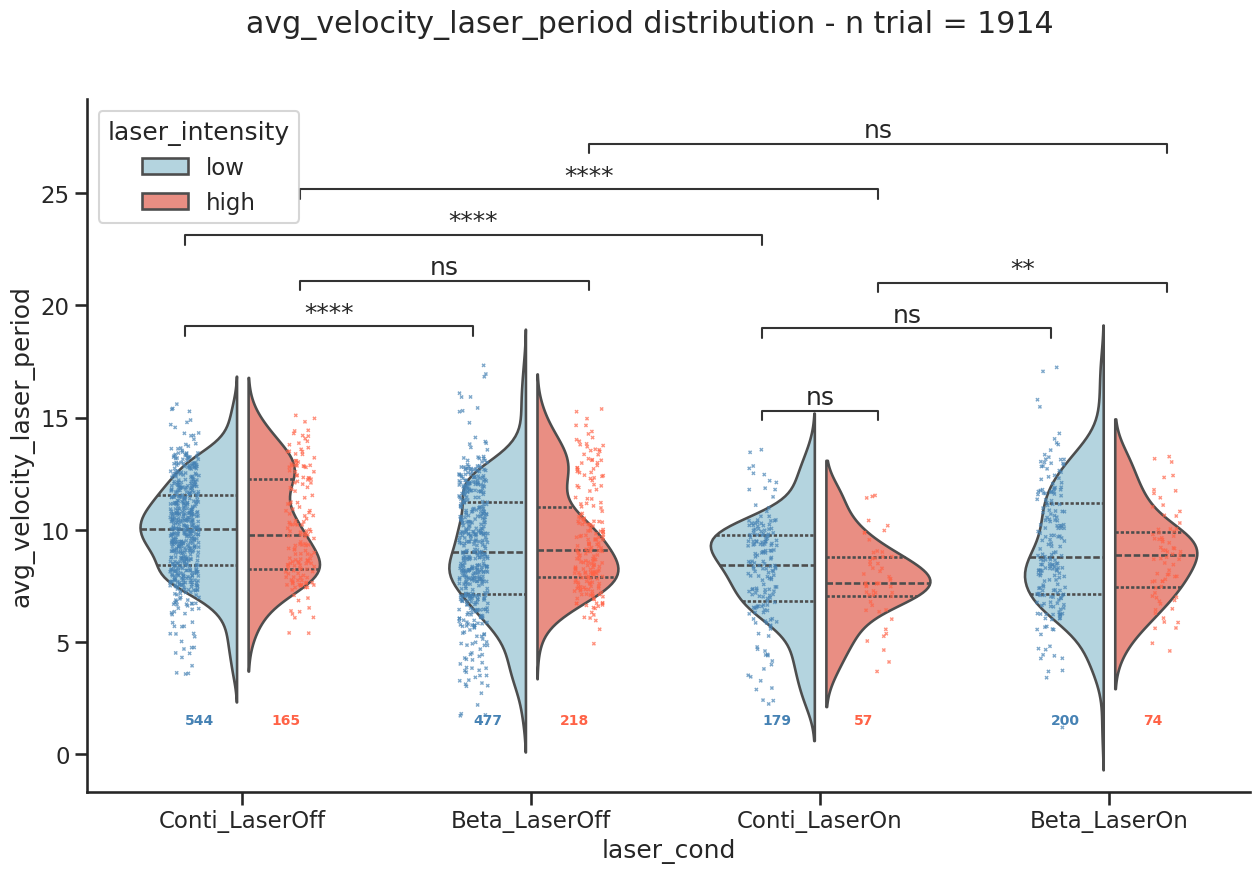

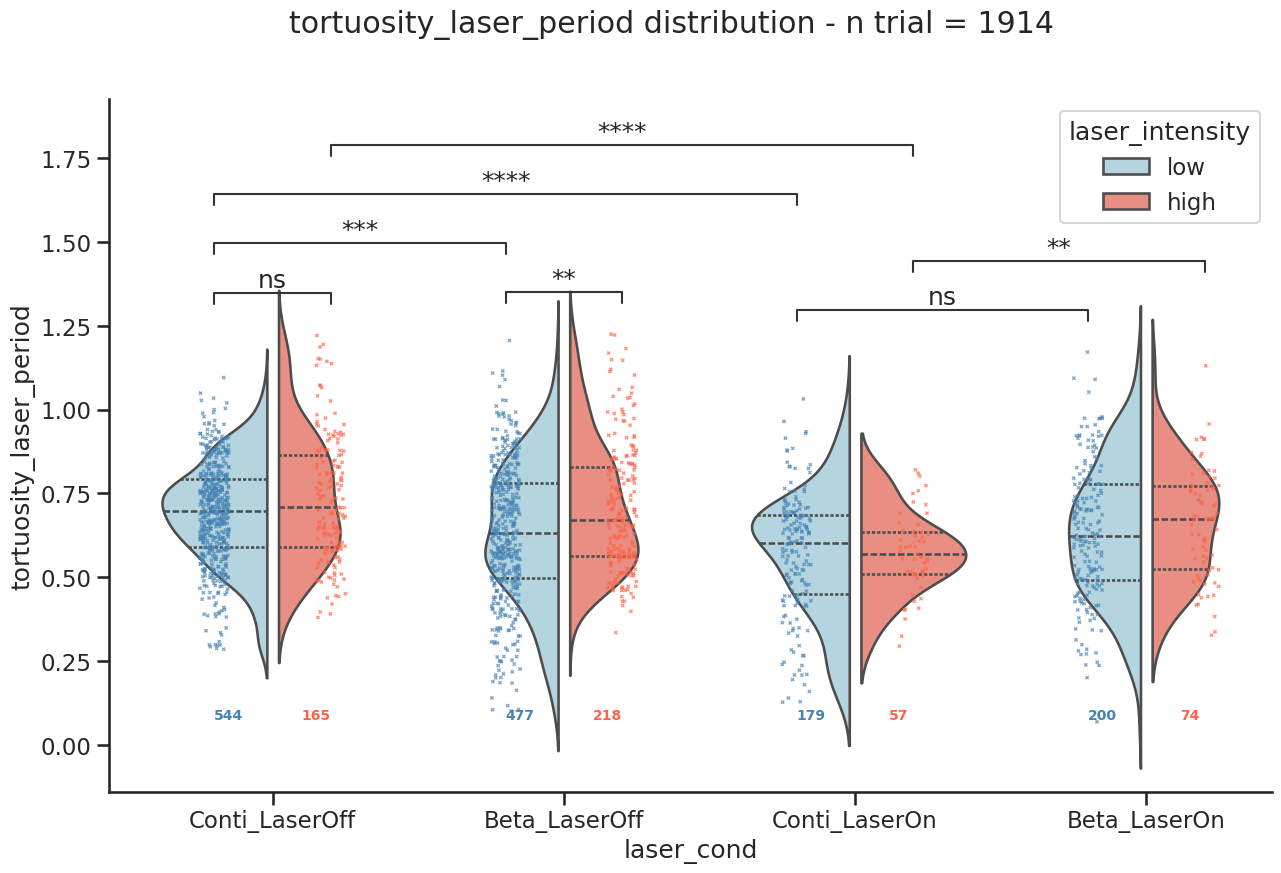

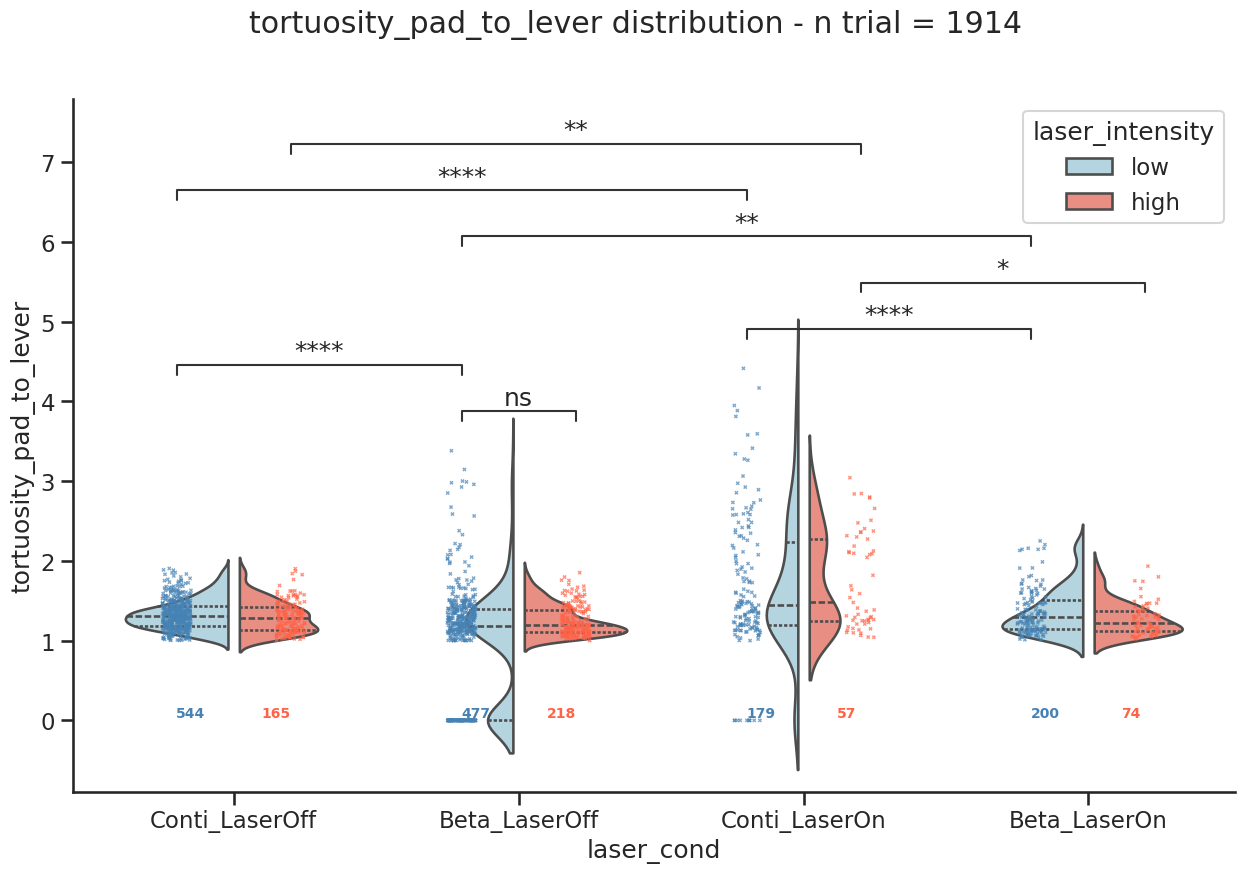

In [6]:
for metric in metrics: 
    print(metric)
    project.trialgroup.violin_statistic(comparisons, metric=metric, 
                                     save_as=u.make_path(analysis_dir / "distribution" / bodypart, f"{metric}.svg"))

Laser Off merged

In [7]:
comparisons_merge_Off = [
    # conti vs beta
    ("Conti.low",  "Beta.low"),
    ("Conti.high", "Beta.high"),

    # low vs high
    ("LaserOff.high", "Conti.high"),
    ("LaserOff.high",  "Beta.high"),
    ("LaserOff.low",    "Beta.low"),
    ("LaserOff.low",   "Conti.low"),

    # condition high vs condition low
    ("Conti.low", "Conti.high"),
    ("Beta.low",  "Beta.high"),

    # Beta high ON vs Conti low ON 
    # (because conti low is suppose to be as damagefull as the beta high)
    ("Beta.high", "Conti.low"),
    ("Beta.low", "Conti.high")
]

avg_velocity_laser_period

Shapiro :
   laser_cond laser_intensity       n  shapiro_stat       p_value
0       Beta            high    74.0      0.986627  6.277630e-01
1       Beta             low   200.0      0.956376  8.178269e-06
2      Conti            high    57.0      0.969870  1.654927e-01
3      Conti             low   179.0      0.978193  6.595201e-03
4   LaserOff            high   383.0      0.958453  6.184476e-09
5   LaserOff             low  1021.0      0.992262  3.507702e-05

Kruskal :
 n_groups        1.0
kruskal_stat    NaN
p_value         NaN
dtype: float64
          group1      group2    n1   n2    U_stat       p_value
0      Conti.low    Beta.low   179  200   15103.0  8.627607e-03
1     Conti.high   Beta.high    57   74    1386.0  7.959644e-04
2  LaserOff.high  Conti.high   383   57   16547.0  3.243666e-10
3  LaserOff.high   Beta.high   383   74   17111.0  4.709120e-03
4   LaserOff.low    Beta.low  1021  200  112046.0  2.918412e-02
5   LaserOff.low   Conti.low  1021  

/home/poemiti/IMN_Kinematics/src/BetaMouv/TrialGroup.py:892: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return (df.groupby(list(group_cols), group_keys=False)


tortuosity_laser_period

Shapiro :
   laser_cond laser_intensity       n  shapiro_stat       p_value
0       Beta            high    74.0      0.985859  5.808620e-01
1       Beta             low   200.0      0.968912  2.076883e-04
2      Conti            high    57.0      0.971517  1.972998e-01
3      Conti             low   179.0      0.982167  2.177997e-02
4   LaserOff            high   383.0      0.967473  1.582546e-07
5   LaserOff             low  1021.0      0.990106  2.270223e-06

Kruskal :
 n_groups        1.0
kruskal_stat    NaN
p_value         NaN
dtype: float64
          group1      group2    n1   n2    U_stat       p_value
0      Conti.low    Beta.low   179  200   15038.0  7.198565e-03
1     Conti.high   Beta.high    57   74    1361.0  5.199617e-04
2  LaserOff.high  Conti.high   383   57   16266.0  2.330128e-09
3  LaserOff.high   Beta.high   383   74   16505.0  2.485648e-02
4   LaserOff.low    Beta.low  1021  200  110936.0  5.267523e-02
5   LaserOff.low   Conti.low  1021  17

/home/poemiti/IMN_Kinematics/src/BetaMouv/TrialGroup.py:892: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return (df.groupby(list(group_cols), group_keys=False)


tortuosity_pad_to_lever

Shapiro :
   laser_cond laser_intensity       n  shapiro_stat       p_value
0       Beta            high    74.0      0.681728  2.219392e-11
1       Beta             low   200.0      0.497303  1.484343e-23
2      Conti            high    57.0      0.879029  3.756838e-05
3      Conti             low   179.0      0.606649  4.672693e-20
4   LaserOff            high   383.0      0.735888  3.165413e-24
5   LaserOff             low  1021.0      0.407763  2.159713e-49

Kruskal :
 n_groups        1.0
kruskal_stat    NaN
p_value         NaN
dtype: float64
          group1      group2    n1   n2   U_stat       p_value
0      Conti.low    Beta.low   179  200  22851.0  3.289788e-06
1     Conti.high   Beta.high    57   74   2824.0  9.097188e-04
2  LaserOff.high  Conti.high   383   57   6688.0  2.367945e-06
3  LaserOff.high   Beta.high   383   74  13563.0  5.591515e-01
4   LaserOff.low    Beta.low  1021  200  92712.0  3.905706e-02
5   LaserOff.low   Conti.low  1021  179  562

/home/poemiti/IMN_Kinematics/src/BetaMouv/TrialGroup.py:892: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return (df.groupby(list(group_cols), group_keys=False)


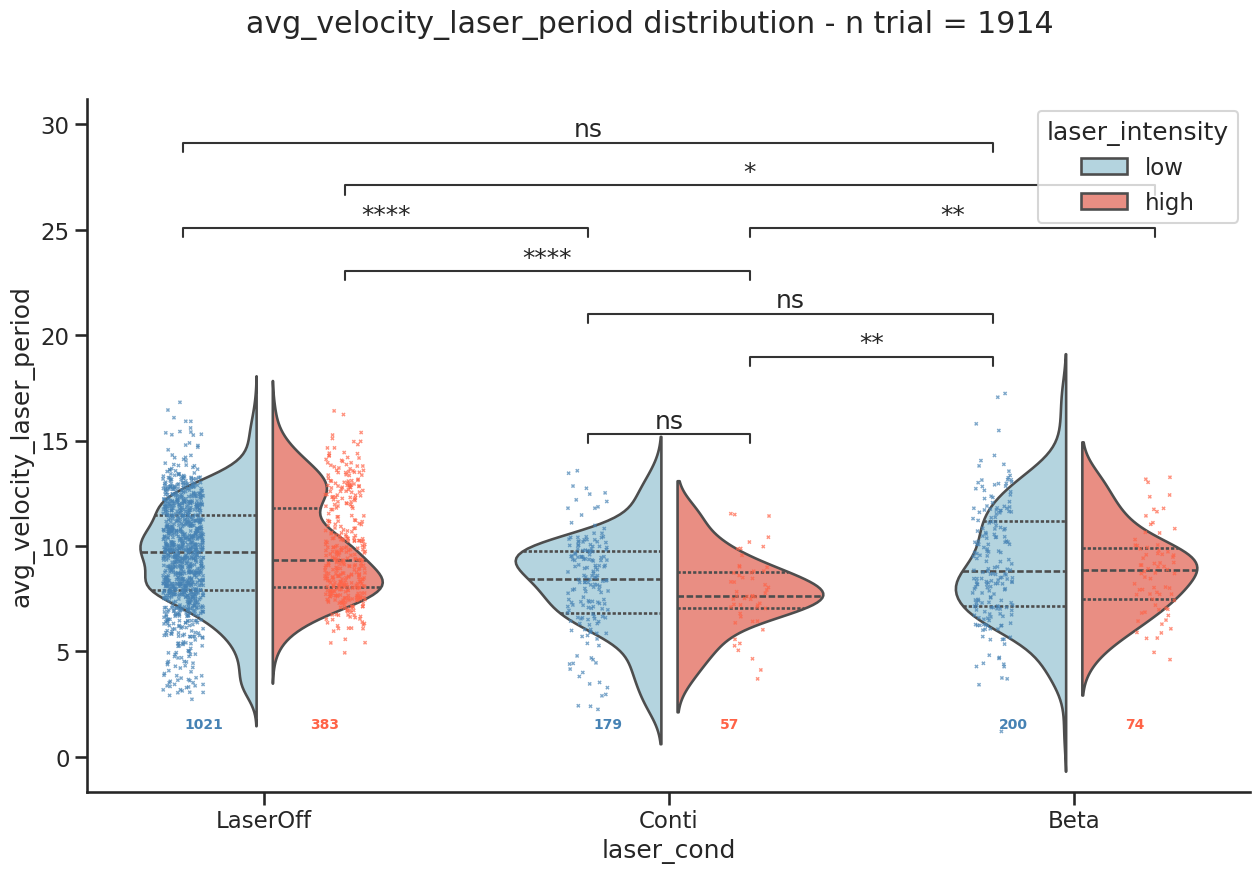

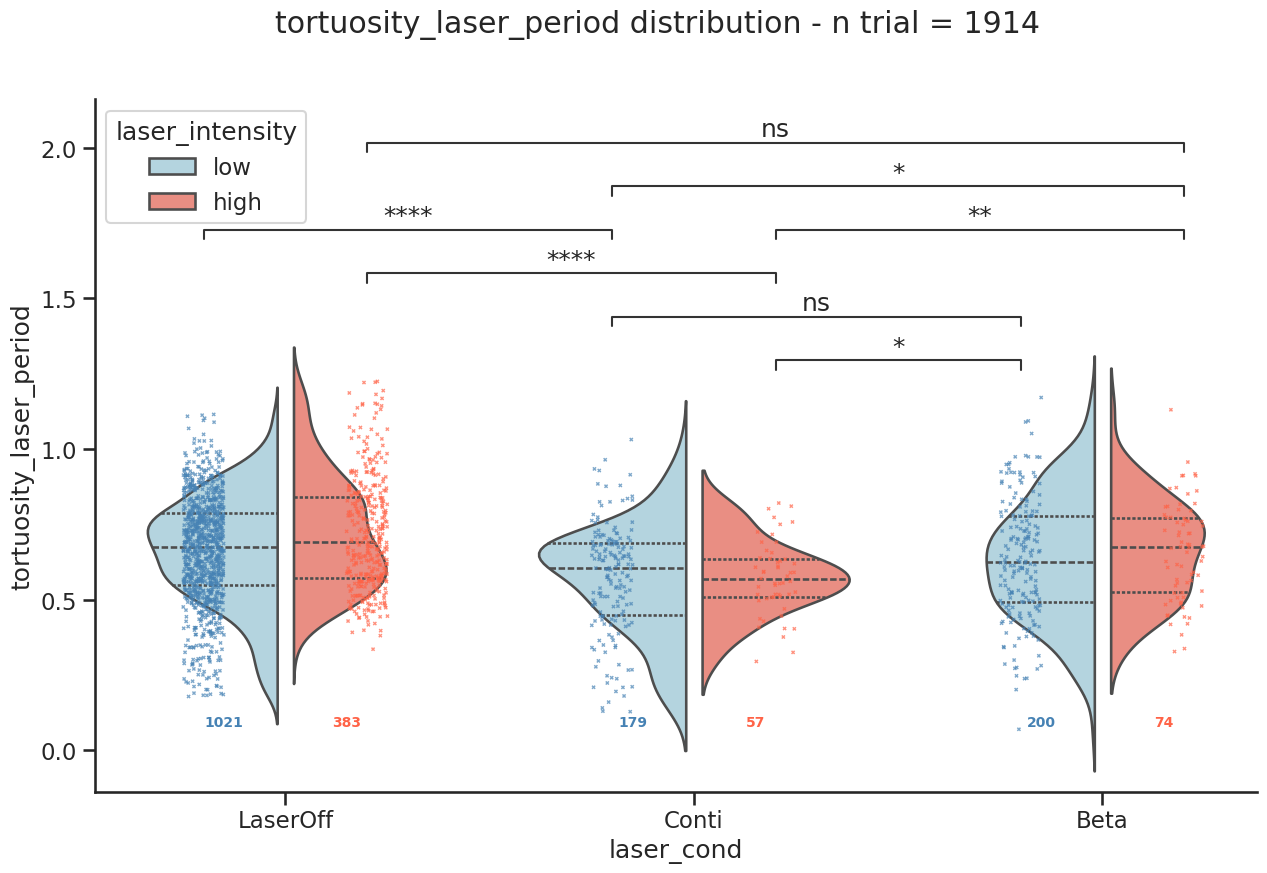

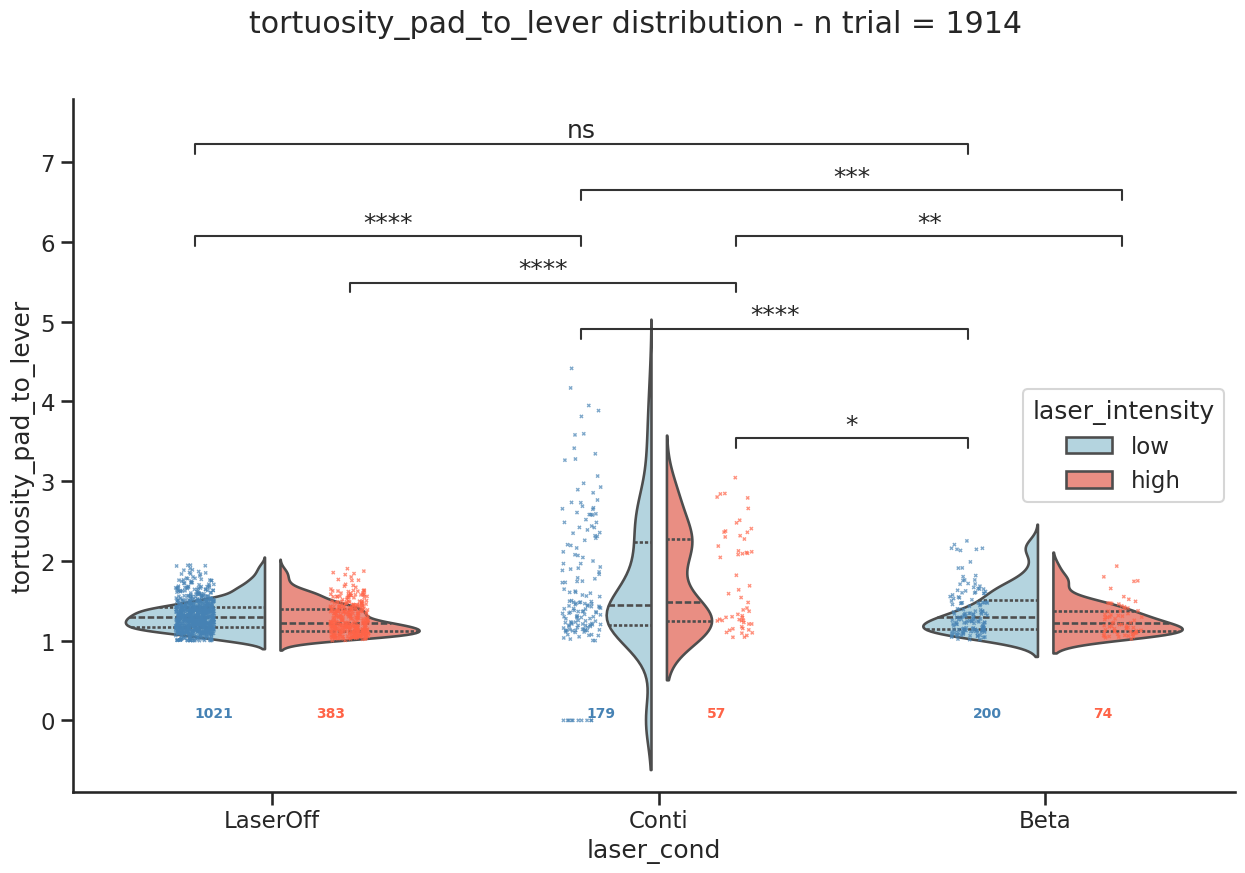

In [8]:
for metric in metrics: 
    print(metric)
    project.trialgroup.violin_statistic(comparisons_merge_Off, metric=metric,  merge_Off=True,
                                     save_as=u.make_path(analysis_dir / "distribution" / bodypart, f"{metric}_merged_off.svg"),
                                     order=["LaserOff", "Conti", "Beta"])


## Single traj timeseries analysis

In [ ]:
for trial in tqdm(project.trialgroup.trials, desc="plotting timeseries"): 
    if not trial.is_valid(): 
        continue
    
    traj: TrajectoryDLC = trial.trajectories.get(bodypart)

    if not traj.is_valid(): 
        continue

    fig, ax = plt.subplots()

    ax = traj.plot_traj(traj.coords, ax, fig, color = "orange", label="raw")
    ax = traj.plot_traj(traj.interpolated_coords, ax, fig, color = "green", label="interpolated")
    ax = traj.plot_traj(traj.clean_coords, ax, fig, color = "blue", label="clean")


    name = trial.name
    title = name[:len(name)//2] + "\n" + name[len(name)//2:]

    ax.set(
        title=title,
        xlabel="X position (cm)",
        ylabel="Y position (cm)",
    )
    fig.savefig(u.make_path(analysis_dir / "traj_per_trial" / bodypart, f"{trial.name}.svg"))
    plt.close()

    for val in timeseries_metric: 

        traj.plot_tendency(value=val, time_pad_off=trial.time_pad_off,
                           laser_state=trial.laser_state,
                           group=trial.group,
                           show_angle= val == "angle",
                           save_as=u.make_path(analysis_dir / "tendency_per_trial" / bodypart / trial.name , f"{val}.svg"))


### DLCTracking animation

In [ ]:
path = Path("/home/ninjayu/IMN_Kinematics/data/BetaMouv/raw/subject_#531/Rat_#531LeftHanded_20240705_ContiMT300_0,75mW_RightHemiCHR_L1L25050_C001H001S0002/"
    "pred_results_Rat_#531LeftHanded_20240705_ContiMT300_0,75mW_RightHemiCHR_L1L25050_C001H001S0002_clip_01.csv")
df = pd.read_csv(path, header=[0, 1, 2], index_col=0)
df = df.droplevel(0, axis=1)
df = df.iloc[1:].reset_index(drop=True)
df.index = np.arange(len(df)) / 125
df.index.name = "t"
df

In [ ]:
df_long = (
    df.stack(level=0)
      .reset_index()
      .rename(columns={'level_1': 'bodypart'})
      .rename_axis(None, axis=1)
)
df_long

In [ ]:
skeleton=[
    ("wrist", "hand"),
    ("hand", "soft_pad"),
    ("hand", "finger_1"),
    ("hand", "finger_2"),
    ("hand", "finger_3"),
]
times = sorted(df_long["t"].unique())
parts = sorted(df_long["bodyparts"].unique())

# Pivot once for fast lookup: one row per (t, bodypart)
coords = df_long.set_index(["t", "bodyparts"])[["x", "y"]]

In [ ]:
import plotly.graph_objects as go

times = sorted(df_long["t"].unique())
parts = sorted(df_long["bodyparts"].unique())

# Pivot once for fast lookup: one row per (t, bodypart)
coords = df_long.set_index(["t", "bodyparts"])[["x", "y"]]


def frame_data(t):
    sub = coords.loc[t]  # index: bodyparts, columns: x, y

    # Points
    pts = go.Scatter(
        x=sub["x"], y=sub["y"],
        mode="markers",
        text=sub.index,
        hoverinfo="text",
        marker=dict(size=8),
        name="bodyparts",
    )

    # Skeleton: a single trace, bones separated by None
    xs, ys = [], []
    for a, b in skeleton:
        if a in sub.index and b in sub.index:
            xs += [sub.at[a, "x"], sub.at[b, "x"], None]
            ys += [sub.at[a, "y"], sub.at[b, "y"], None]
    bones = go.Scatter(
        x=xs, y=ys,
        mode="lines",
        line=dict(width=2, color="gray"),
        hoverinfo="skip",
        name="skeleton",
    )
    return [bones, pts]  # bones first so points are drawn on top


fig = go.Figure(
    data=frame_data(times[0]),
    frames=[go.Frame(data=frame_data(t), name=str(t)) for t in times],
)

fig.update_layout(
    xaxis=dict(range=[0, 250], constrain="domain"),
    yaxis=dict(range=[350, 150], scaleanchor="x",),  # keep aspect ratio 1:1
    updatemenus=[dict(
        type="buttons",
        buttons=[
            dict(label="Play", method="animate",
                 args=[None, dict(frame=dict(duration=50, redraw=True),
                                  fromcurrent=True)]),
            dict(label="Pause", method="animate",
                 args=[[None], dict(frame=dict(duration=0, redraw=False),
                                    mode="immediate")]),
        ],
    )],
    sliders=[dict(
        steps=[dict(method="animate",
                    args=[[str(t)], dict(mode="immediate",
                                         frame=dict(duration=0, redraw=True))],
                    label=str(t))
               for t in times],
    )],
)

fig.write_html("skeleton_animation.html", auto_open=True)